In [ ]:
# Empty for "ruff" extension

# Batch algorithm for Near-Duplicates Detection


In [1]:
import sys
import pyspark.sql.functions as F
from pathlib import Path
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent))

from src.spark_utils import get_spark
from src.datasets import read_synthetic

spark = get_spark()

%load_ext autoreload
%autoreload 2

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/homebrew/anaconda3/envs/pyspark-dev/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/13 17:41:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


/opt/homebrew/anaconda3/envs/pyspark-dev/lib/python3.14/site-packages/pyspark/sql/pandas/functions.py:777: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/anaconda3/envs/pyspark-dev/lib/python3.14/site-packages/pyspark/sql/pandas/typehints.py:60: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


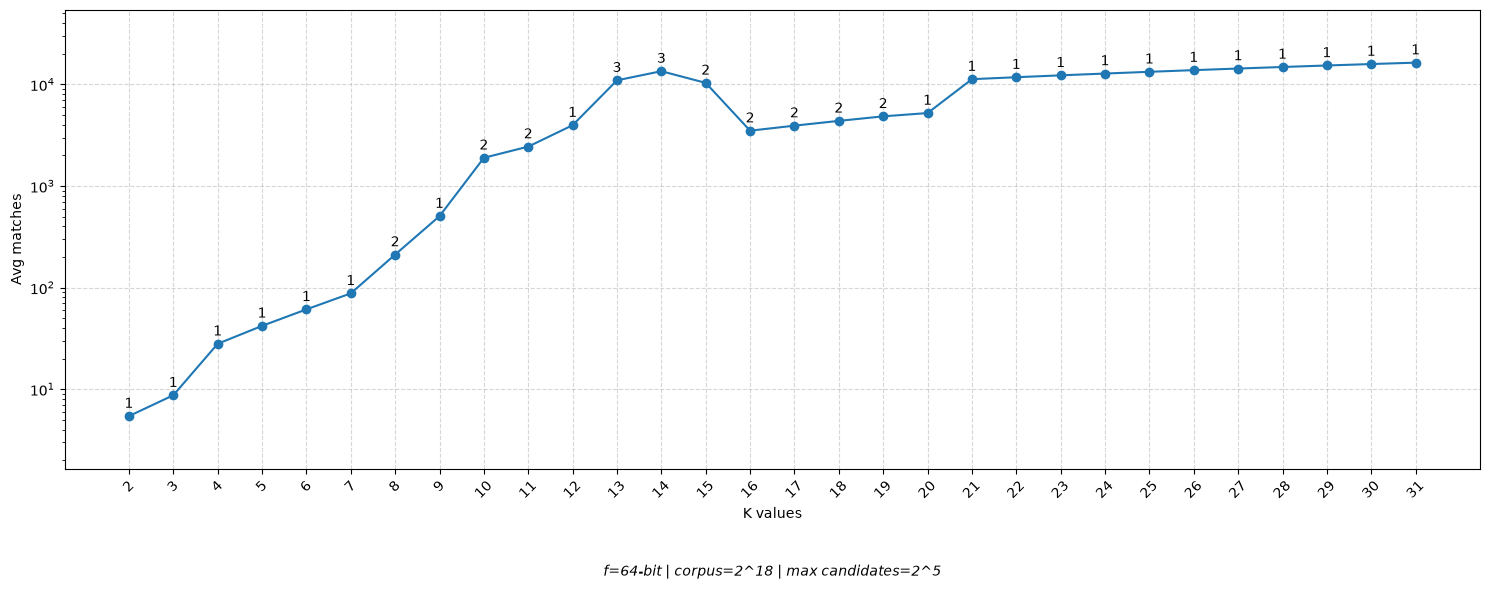

In [2]:
from src.near_duplicates import partitions_schema
import math


f = 64
p_min = 5
d = 18
probe_stats = []
iterations_needed = []

for K in range(2, int(f // 2)):
    tables = partitions_schema(f=f, K=K, d=d,p_min=p_min)
    # Bits "covered" by the partitions (that are certainly equals)
    partition_bits = sum((table["r"] - K) * table["block_bits"] for table in tables[1])
    combos = tables[0]
    iterations_needed.append(len(tables[1]))
    # Possible matches for each corpus row
    matches = combos * math.pow(2, d / partition_bits)
    probe_stats.append((K, matches))

### PLOT ###
df_stats = pd.DataFrame(
    probe_stats, columns=["K", "Avg matches"]
).astype({"K": str}).set_index("K")
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df_stats.index, df_stats["Avg matches"], marker="o")
ax.set(yscale="log", xlabel="K values", ylabel="Avg matches")
for (x, y), label in zip(df_stats["Avg matches"].items(), iterations_needed): # Number of partitions, over points
    ax.annotate(str(label), (x, y), textcoords="offset points", xytext=(0, 6), ha="center")
ax.grid(True, linestyle="--", alpha=0.5) # Linestyle
ax.margins(y=0.15) # Automargins
plt.xticks(rotation=45)
ax.set_title( # Bottom text
    f"f={f}-bit | corpus=2^{d} | max candidates=2^{p_min}",
    fontsize=10, style="italic", y=-0.25
)
plt.tight_layout()
plt.show()

In [ ]:
import time

from src.fingerprint import ShingleParams, create_fingerprints
from src.near_duplicates import detect_near_duplicate_batch
from src.datasets import read_c5
import math

# Other params are inherited from previous block
f = 64
p_min = 10
ID_COL = "ID"
INPUT_DATA_COL = "data"
PURPOSE = "run" # benchmark / run
benchmark_results = []

if PURPOSE == "benchmark":
    Ks = [7, 8]
    f = 64 # Must be 64 bits, the benchmark dataset is made of 64 bits values
    corpus_sizes = [10000, 100000, 250000, 500000] # max size - 1
    # query_sizes = [200, 2000, 20000, 100000] # 20% of corpus
    query_sizes_ratio = 0.2
    query_sizes = [int(c_size * query_sizes_ratio) for c_size in corpus_sizes]
    fingerprints = read_synthetic()
    fingerprints.cache()
    for c_size, q_size in zip(corpus_sizes, query_sizes):
        corpus = fingerprints.limit(c_size)
        query = fingerprints.limit(q_size)
        for K in Ks:
            start_time = time.perf_counter()
            result = detect_near_duplicate_batch(corpus, query, f, K=K, d=int(math.log(c_size, 2)), p_min=10).count()
            end_time = time.perf_counter()
            benchmark_results.append({"K": K, "corpus_size": c_size, "query_size": q_size, "time": (end_time - start_time) * 1000})
elif PURPOSE == "run":
    K = 3
    input_df = read_c5()
    input_df.count()
    fingerprints = create_fingerprints(df=input_df, model="tf-idf", input_col=INPUT_DATA_COL, output_col="fingerprint", fingerprint_size=f, other=None).select(ID_COL, "fingerprint")
    corpus, query = fingerprints.randomSplit([0.8, 0.2])
    corpus_size = corpus.count()
    start = time.perf_counter()
    duplicates = detect_near_duplicate_batch(corpus, query, 64, K, int(math.log(corpus_size, 2)), 5)
    duplicates_count = duplicates.count()
    end = time.perf_counter()
    print(duplicates_count, (end - start) * 1000)
else:
    raise ValueError("Invalid purpose")

In [ ]:
if PURPOSE == "benchmark":
    df = pd.DataFrame(benchmark_results)
    df["K"] = df["K"].astype(str)
    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=df,
        x="corpus_size",
        y="time",
        hue="K",
        marker="o"
    )
    plt.title("Execution Time vs. Corpus Size by K")
    plt.xlabel("Corpus Size")
    plt.ylabel("Time (ms)")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.show()

In [ ]:
import pyspark.sql.functions as F

if PURPOSE == "run":
    """
    joined_df = duplicates.alias("a").join(input_df.alias("b"), F.col("a.ID_corpus") == F.col("b.ID")).drop("ID").withColumnRenamed("data", "data_corpus")
    joined_df = joined_df.alias("a").join(input_df.alias("b"), F.col("a.ID_query") == F.col("b.ID")).drop("ID").withColumnRenamed("data", "data_query")
    joined_df = joined_df.filter(joined_df.data_corpus != joined_df.data_query).limit(5)

    joined_df.toPandas().to_csv("c5_duplicates_sample.csv")
    """
    print(duplicates.count())

In [ ]:
spark.stop()